# PlantAI — Notebook mestre

AFYA | UNIMA Maceió — Inteligência Artificial. Resumo executável: dados reais → ML/Visão → PLN → decisão → integração.

| Critério | Evidência |
|---|---|
| Problema e arquitetura | `Docs/architecture.md`, `src/contracts.py` |
| Machine Learning | Exp 1–3 (`src/ml/`) |
| Visão Computacional | `src/vision/` (processador + MobileNetV2) |
| PLN | `src/nlp/` (sintomas + intenção) |
| Decisão | `src/decision/decision_rules.py` (6 regras) |
| Integração | `CoordinatorAgent.answer` |
| Experimentos | `results/`, `Docs/experiments.md` |

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
from IPython.display import Image, display
M = ROOT / 'results' / 'metrics'
def show(name): display(Image(filename=str(ROOT / 'results' / name), width=620))


In [2]:
display(pd.read_csv(M/'summary_all_experiments.csv')[['experiment_id','dataset_name','num_samples','accuracy','f1_macro']])

,experiment_id,dataset_name,num_samples,accuracy,f1_macro
0,exp1_baseline_majority,PlantVillage (teste),1097,0.2479,0.0662
1,exp1_baseline_vision,PlantVillage (teste),1097,0.6044,0.6224
2,exp2_classic_descriptors,PlantVillage (teste),1097,0.9672,0.9661
3,exp2_transfer_learning,PlantVillage (teste),1097,0.9763,0.9752
4,exp4_nlp_lr,"Corpus de sintomas (CV 5-fold fora-da-dobra, N...",180,0.8278,0.8277
5,exp4_nlp_svm,"Corpus de sintomas (CV 5-fold fora-da-dobra, N...",180,0.8389,0.8389
6,exp6_generalization_plantdoc,"PlantDoc (campo, N=586)",586,0.4386,0.3678
7,exp6_domain_adaptation,"PlantDoc (50% reservado, N=293)",293,0.5666,0.5638


In [3]:
from src.agents import CoordinatorAgent
co = CoordinatorAgent()
r = co.answer(ROOT/'results'/'exemplos'/'plantvillage_Potato_Late_blight.jpg', 'Folhas pretas e encharcadas com mofo branco após a chuva. Isso é grave?')
print(co.generate_report(r.decision)); print('\nRESPOSTA:', r.answer)

  PLANTAI - RELATÓRIO DE DIAGNÓSTICO MULTIAGENTE
Status da Decisão    : CONFIRMADO_POR_MULTIPLAS_EVIDENCIAS
Regra Acionada       : R03_EXACT_CONCORDANCE_BOOST
Modo de Operação     : integrated
Classe Identificada  : Potato___Late_blight
Cultura / Doença     : Batata (Solanum tuberosum) — Requeima da Batateira
Agente Etiológico    : Phytophthora infestans
Confiança Consolidada: 88.59%
------------------------------------------------------------------------------
[1] SAÍDAS DOS AGENTES ESPECIALISTAS (CONTRATO PADRONIZADO):
  • VisionAgent (MobileNetV2): Top-1='Potato___Late_blight' (conf=100.00%) | Top-K=[Potato___Late_blight (100.0%), Potato___Early_blight (0.0%), Tomato___Late_blight (0.0%)]
    Qualidade Visual: válida=True | brilho=113.37 | nitidez=240.73
  • NLPAgent (TF-IDF + ML)   : Top-1='Potato___Late_blight' (conf=56.11%) | Top-K=[Potato___Late_blight (56.1%), Tomato___Late_blight (38.2%), Tomato___Early_blight (2.1%)]
    Sintomas Extraídos: ['lesoes_encharcadas', 'mofo_esbran

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


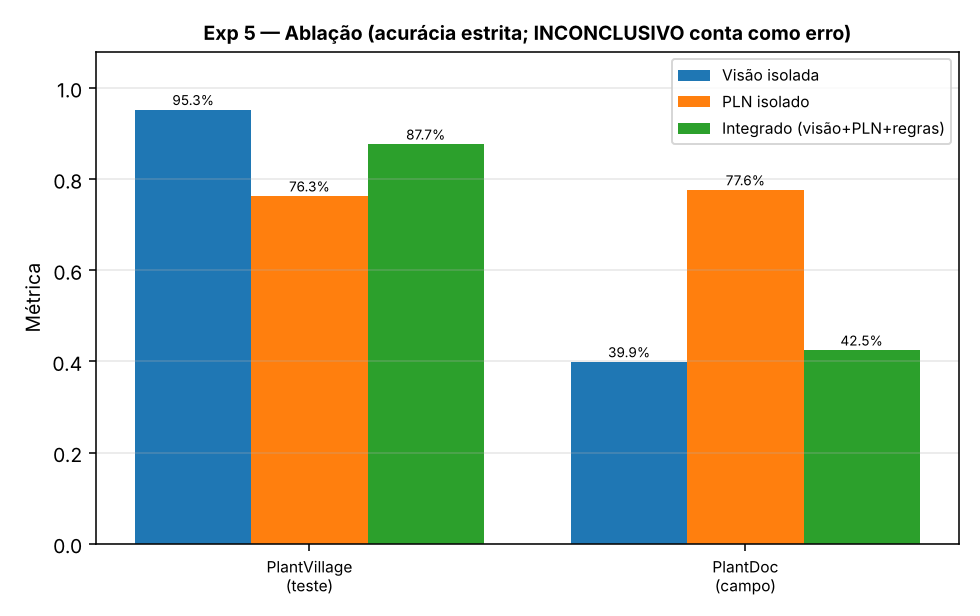

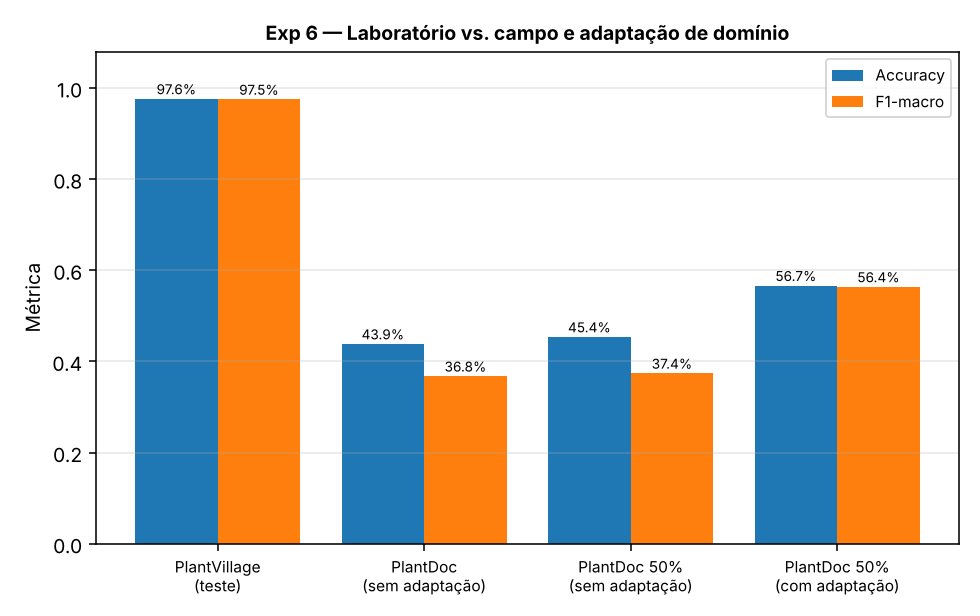

In [4]:
show('plots/exp5_multiagent_ablation.png'); show('plots/exp6_generalization_comparison.png')